# Deming Regression for the Tully-Fisher Relation

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 6 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

In Chapters 4 and 5 we developed techniques to model the relation between two variables when the dependent variable has uncertainties. When the dependent variable $y$ has measurement errors, we can handle them with weighted least squares or Bayesian inference. But the independent variable $x$ can carry measurement uncertainties too.

The Tully-Fisher relation is an astronomical laboratory for this problem. This scaling law links the rotation velocity of a galaxy to its total baryonic mass, the mass of its stars and gas. It is a cosmic distance indicator and a probe of the physics of galaxy formation. Both quantities carry uncertainties. The rotation velocities come from spectroscopic observations, and the masses come from photometric measurements.

Ordinary least squares (OLS) is the standard straight-line fit of Chapter 4. It minimizes the sum of the squared vertical distances between the points and the line. This is the maximum likelihood estimate when the noise in $y$ is Gaussian with constant size. OLS treats the independent variable as exact, so it ignores its uncertainties, and this causes a problem.

The measurement errors in the velocity make the observed distribution of velocities wider than the true distribution. Think of it this way. If the measured velocity of every galaxy includes random noise, the cloud of points spreads out horizontally on our plot. This widening has no matching effect on the vertical spread, so the relation appears shallower than it truly is.

This underestimate of the slope is called **attenuation bias** or **regression dilution**. The word "attenuation" means weakening, because the measurement uncertainties weaken the observed relation. This is not a random error that averages out with more data. With infinitely many galaxies, we still underestimate the slope by a predictable amount if we ignore the velocity uncertainties.

In this tutorial, we use real galaxy data from the SPARC (Spitzer Photometry and Accurate Rotation Curves) survey ([Lelli et al. 2016](https://ui.adsabs.harvard.edu/abs/2016AJ....152..157L/abstract)). First, we show attenuation bias in simulations and compare it with its mathematical form. The bias depends on the ratio of the measurement uncertainty to the intrinsic spread of the data. Then we implement Deming regression, which treats the true velocities as latent variables and infers them together with the slope. Finally, we compare OLS and Deming regression for the galaxies.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Python programming with NumPy arrays and matplotlib plots
- Linear regression, in particular maximum likelihood estimation and residuals
- Summary statistics and transformations of random variables
- The bootstrap, a resampling method to estimate uncertainties

### Learning Objectives

After this tutorial you can do the following.

- Show how measurement uncertainties in the independent variable bias an OLS fit
- Fit a line with errors in both variables, with an analytical and a numerical Deming regression
- Compute the attenuation factor and predict the size of the bias from the measurement uncertainties
- Extend Deming regression to uncertainties that differ from point to point
- Compare OLS and Deming regression on real data

We begin by importing the libraries and setting the plot style.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Fix the random seed
np.random.seed(42)

## The SPARC Galaxy Dataset

The SPARC database is a laboratory for the study of the Tully-Fisher relation. It has 175 nearby disk galaxies. They have Spitzer Space Telescope photometry at 3.6 $\mu$m. Their rotation curves come from radio observations of neutral hydrogen (HI) and optical observations of ionized hydrogen (H$\alpha$). This tutorial uses the 85 spiral galaxies, of types Sa to Sd, with a flat outer rotation curve.

Near-infrared photometry traces the stellar mass well, because dust and recent star formation affect it little. SPARC takes the stellar mass from the 3.6 $\mu$m luminosity and the gas mass from the HI observations. The baryonic mass is their sum.

For this tutorial, we extracted four quantities from SPARC. They are the logarithms of the flat rotation velocity $V$ in km/s and of the baryonic mass $M_b$ in units of $10^9$ solar masses. The other two are the measurement uncertainty of each logarithm, in dex. One dex is a factor of 10.

These logarithmic quantities suit the Tully-Fisher relation, which is a power law between velocity and mass.

Velocity measurements face several difficulties. The tilt of the disk, called the inclination, is hard to measure and becomes very uncertain for face-on galaxies. Non-circular motions of the gas may not trace the gravitational potential exactly.

The uncertainties reported by SPARC are much smaller for the mass than for the velocity, as the data below show. The mass uncertainty comes from the 3.6 $\mu$m photometry alone, which is precise to about 1% for these galaxies. It excludes the larger uncertainties of the distance and of the conversion from light to mass. The independent variable, the velocity, thus carries the larger reported uncertainty. This makes the Tully-Fisher relation a good case for Deming regression, which uses the uncertainties of both variables. We now load the data.

In [2]:
# Load the prepared SPARC dataset
data = np.load('../data/dataset_tully_fisher.npz')
x_gal = data['logV']
sigma_x_gal = data['e_logV']
y_gal = data['log_M_b']
sigma_y_gal = data['e_log_M_b']

print(f"Median velocity uncertainty = {np.median(sigma_x_gal):.3f} dex")
print(f"Median mass uncertainty = {np.median(sigma_y_gal):.3f} dex")

Median velocity uncertainty = 0.016 dex
Median mass uncertainty = 0.003 dex


## Visualizing the Tully-Fisher Relation

The Tully-Fisher relation states that the rotation velocity $V$ of a galaxy is related to its baryonic mass $M_b$ through a power law

$$M_b \propto V^{\gamma},$$

where empirical studies typically find $\gamma \approx 3$ to 4. This power law follows from the virial theorem, which links speed and mass in a bound system, and from the dynamics of rotating disks. For a galaxy in dynamical equilibrium, the rotation velocity at a given radius depends on the enclosed mass. For the characteristic velocity and the total mass, a power law arises. When we take the logarithm of both sides, the power law becomes linear

$$\log M_b = \gamma \log V + c.$$

The input is $x = \log V$, the output is $y = \log M_b$, $\gamma$ is the slope and $c$ is the intercept. We now plot the galaxies with their error bars, and the errors of both variables relative to the spread of each variable.

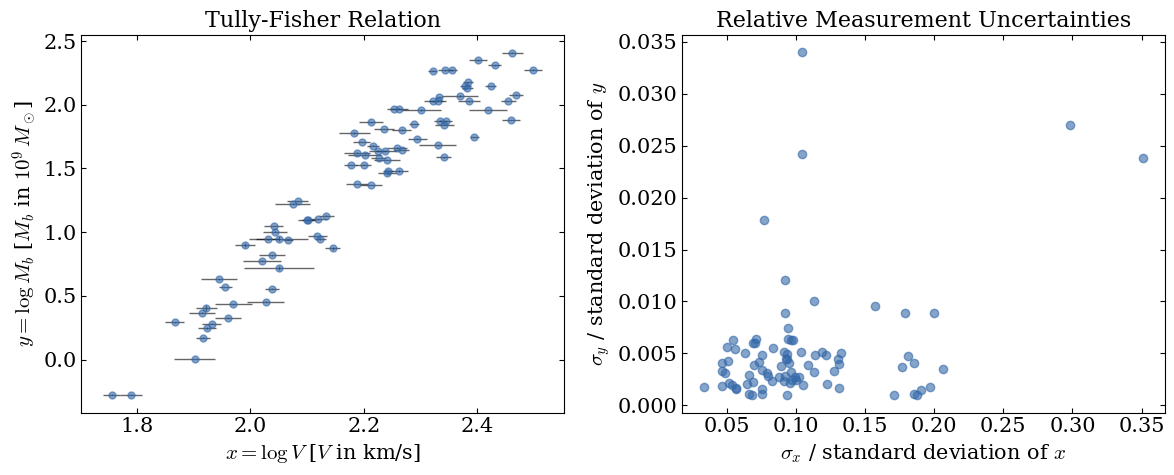


Median relative uncertainties, in units of the standard deviation
X-axis (velocity) = 9.3%
Y-axis (mass) = 0.4%


In [3]:
# Visualize the Tully-Fisher relation with uncertainties
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left panel with the data and the error bars in x and y
ax1.errorbar(x_gal, y_gal,
             xerr=sigma_x_gal, yerr=sigma_y_gal,
             fmt='o', markersize=5, alpha=0.6,
             ecolor='black', elinewidth=1, capsize=0)
ax1.set_xlabel(r'$x = \log V$ [$V$ in km/s]')
ax1.set_ylabel(r'$y = \log M_b$ [$M_b$ in $10^9\,M_\odot$]')
ax1.set_title('Tully-Fisher Relation')

# Right panel with the relative errors
ax2.scatter(sigma_x_gal/np.std(x_gal),
            sigma_y_gal/np.std(y_gal),
            alpha=0.6)
ax2.set_xlabel(r'$\sigma_x$ / standard deviation of $x$')
ax2.set_ylabel(r'$\sigma_y$ / standard deviation of $y$')
ax2.set_title('Relative Measurement Uncertainties')

plt.tight_layout()
plt.show()

# Calculate the median relative errors
median_rel_x = np.median(sigma_x_gal) / np.std(x_gal)
median_rel_y = np.median(sigma_y_gal) / np.std(y_gal)
print("\nMedian relative uncertainties, in units of the standard deviation")
print(f"X-axis (velocity) = {median_rel_x:.1%}")
print(f"Y-axis (mass) = {median_rel_y:.1%}")

The left panel shows the error bars in $x$ and $y$, and the error bars in $y$ are too small to see. The right panel shows that the measurement uncertainties of the two variables are not symmetric. The velocity uncertainties are about 9% of the standard deviation of $x$, and the mass uncertainties are about 0.4% of that of $y$. The independent variable thus carries much more uncertainty than the dependent variable, and OLS treats it as exact.

## Simulating Attenuation Bias

To understand how measurement uncertainties affect regression, we create a controlled simulation. We generate data from a known linear relation, add measurement errors and observe how OLS underestimates the true slope.

In our simulation, the true data points follow $y_{\text{true}} = \gamma x_{\text{true}}$ with $\gamma = 3$. This is our ground truth. We then add Gaussian noise to both $x$ and $y$ to simulate measurement errors, as real astronomical observations contain uncertainties. We fit a line to these noisy observations with OLS and compare the fitted slope with the true slope.

As in Tutorial 4a, the OLS solution is the analytical maximum likelihood solution of Section 4.4, $\mathbf{w}_{\text{ML}} = (\boldsymbol{\Phi}^T\boldsymbol{\Phi})^{-1}\boldsymbol{\Phi}^T\mathbf{t}$. Consider one input and one output, with the data centered on their means, so that the line passes through the origin. Then $\boldsymbol{\Phi}$ is the single column of the observed $x$, and $\mathbf{t}$ is the column of the observed $y$. The matrices become sums, and the solution is the slope

$$\hat{\gamma} = \frac{\sum_i x_{\text{obs},i} y_{\text{obs},i}}{\sum_i x_{\text{obs},i}^2}.$$

The code uses this formula for every OLS slope.

The derivation of OLS assumes that the independent variable $x$ is known exactly and that only $y$ has measurement errors. When these assumptions hold, OLS recovers the true parameters. When $x$ has measurement errors, we treat noisy $x$-values as the true values, and the OLS slope is too low.

In Section 6.3 we derived the expected OLS slope when $x$ has measurement errors

$$\mathbb{E}[\hat{\gamma}] = \alpha\gamma,$$

where the attenuation factor is

$$\alpha = \frac{1}{1 + (\sigma_x/\sigma_{\text{range}})^2}.$$

Here $\sigma_x$ is the measurement uncertainty in $x$, and $\sigma_{\text{range}}$ is the intrinsic spread, the standard deviation, of the true $x$-values. The measurement uncertainties raise the observed variance of $x$ from $\sigma_{\text{range}}^2$ to $\sigma_{\text{range}}^2 + \sigma_x^2$. They leave the covariance of $x$ and $y$ unchanged. The ratio of these two quantities gives the attenuated slope. We now simulate a data set for each of three levels of $x$-uncertainty and fit it with OLS.

In [4]:
# Set the parameters
n_points = 200
true_slope = 3.0
sigma_y = 0.3
x_sd = 1.0  # standard deviation of the true x-values
sigma_x_values = [0.1, 0.5, 1.0]

# Simulate a data set for each level of the x-uncertainty
simulations = []
for sigma_x in sigma_x_values:
    # Generate the true values
    x_true = np.random.normal(0, x_sd, n_points)
    y_true = true_slope * x_true

    # Add the measurement errors
    x_obs = x_true + np.random.normal(0, sigma_x, n_points)
    y_obs = y_true + np.random.normal(0, sigma_y, n_points)

    # Center the observed data
    x_obs = x_obs - np.mean(x_obs)
    y_obs = y_obs - np.mean(y_obs)

    # OLS slope, which assumes no x-uncertainty
    slope_ols = np.sum(x_obs * y_obs) / np.sum(x_obs**2)

    # Calculate the theoretical attenuation factor
    sigma_range = np.std(x_true)
    alpha_theory = 1 / (1 + (sigma_x/sigma_range)**2)

    simulations.append((sigma_x, x_obs, y_obs, slope_ols, alpha_theory))

We plot each data set with the true line and the OLS fit. The title shows the attenuation factor that the formula predicts.

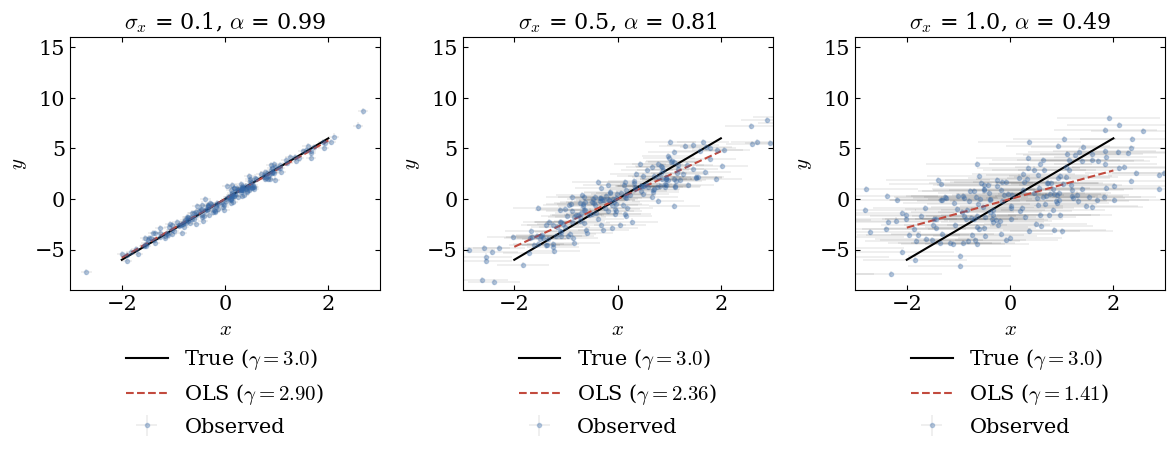

In [5]:
# Plot the data and the fits with error bars
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, (sigma_x, x_obs, y_obs, slope_ols, alpha_theory) in zip(axes, simulations):
    ax.errorbar(x_obs, y_obs, xerr=sigma_x, yerr=sigma_y, fmt='o',
                alpha=0.3, markersize=3, capsize=0, elinewidth=0.3,
                label='Observed', ecolor='black')

    x_line = np.linspace(-2, 2, 100)
    ax.plot(x_line, true_slope * x_line, '-', color='k',
            label=f'True ($\\gamma={true_slope:.1f}$)')
    ax.plot(x_line, slope_ols * x_line, '--', color='C3',
            label=f'OLS ($\\gamma={slope_ols:.2f}$)')

    # Label the axes, add the legend and set the limits
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_title(rf'$\sigma_x$ = {sigma_x:.1f}, $\alpha$ = {alpha_theory:.2f}')
    ax.legend(ncol=1, loc='upper center', bbox_to_anchor=(0.5, -0.15))
    ax.set_xlim(-3, 3)
    ax.set_ylim(-9, 16)

plt.tight_layout()
plt.show()

The simulation shows attenuation bias in action. As the measurement uncertainty in $x$ increases, the OLS slope underestimates the true relation more and more. The attenuation factor $\alpha$ measures this bias. The attenuation factor is 0.99 for a ratio $\sigma_x/\sigma_{\text{range}}$ of 0.1 and 0.92 for a ratio of 0.3. When $\sigma_x$ equals $\sigma_{\text{range}}$, we recover only half of the true slope. The bias depends on the ratio $\sigma_x/\sigma_{\text{range}}$ and not on the sample size, so more data do not remove it.

## The Asymmetry of Measurement Uncertainties

The attenuation factor depends only on the uncertainty of the independent variable, so only this uncertainty causes attenuation bias. To understand this asymmetry, recall that OLS minimizes the squared residuals in the $y$-direction. When $y$ has measurement errors, they add to the residual variance, which the OLS fit already includes. When $x$ has errors, we use incorrect $x$-values to predict $y$, and this flattens the observed relation.

We show this asymmetry with a simulation that has errors in $y$ only. We can compare it with the earlier simulation, where $x$ had errors.

In [6]:
# Set the parameters
n_points = 200
true_slope = 3.0
x_sd = 1.0  # standard deviation of the true x-values
sigma_y_values = [0.1, 0.5, 1.0]

# Simulate a data set for each level of the y-uncertainty
simulations_y = []
for sigma_y in sigma_y_values:
    # Generate the true values
    x_true = np.random.normal(0, x_sd, n_points)
    y_true = true_slope * x_true

    # Add the measurement errors, only in y
    x_obs = x_true.copy()
    y_obs = y_true + np.random.normal(0, sigma_y, n_points)

    # Center the observed data
    x_obs = x_obs - np.mean(x_obs)
    y_obs = y_obs - np.mean(y_obs)

    # OLS slope
    slope_ols = np.sum(x_obs * y_obs) / np.sum(x_obs**2)

    simulations_y.append((sigma_y, x_obs, y_obs, slope_ols))

We plot each data set with the true line and the OLS fit.

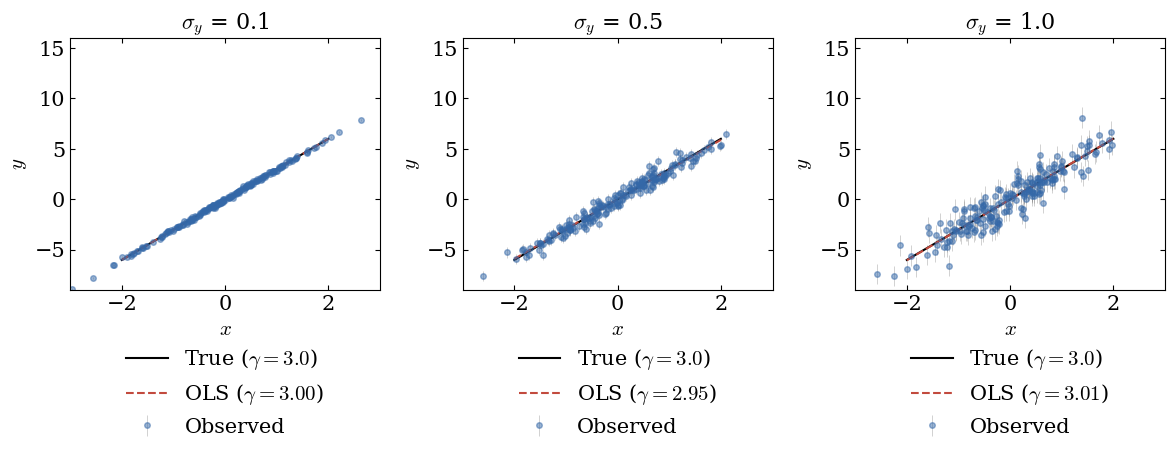

In [7]:
# Plot the data with y error bars
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, (sigma_y, x_obs, y_obs, slope_ols) in zip(axes, simulations_y):
    ax.errorbar(x_obs, y_obs, yerr=sigma_y, fmt='o', markersize=4,
                alpha=0.5, ecolor='gray', elinewidth=0.5, capsize=0,
                label='Observed')

    x_line = np.linspace(-2, 2, 100)
    ax.plot(x_line, true_slope * x_line, '-', color='k',
            label=f'True ($\\gamma={true_slope:.1f}$)')
    ax.plot(x_line, slope_ols * x_line, '--', color='C3',
            label=f'OLS ($\\gamma={slope_ols:.2f}$)')

    # Label the axes, add the legend and set the limits
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_title(rf'$\sigma_y$ = {sigma_y:.1f}')
    ax.legend(ncol=1, loc='upper center', bbox_to_anchor=(0.5, -0.15))
    ax.set_xlim(-3, 3)
    ax.set_ylim(-9, 16)

plt.tight_layout()
plt.show()

Even with a large uncertainty in $y$ ($\sigma_y = 1.0$), OLS recovers the true slope almost perfectly. The error bars show the measurement uncertainty in $y$, yet the fitted slope has no bias. In our earlier simulation, uncertainties in $x$ of the same size caused a large attenuation.

## Implementing Deming Regression

Now that we understand attenuation bias, we implement Deming regression to correct for it. Deming regression uses the uncertainties of both variables. It treats the true $x$-values as latent variables and infers them together with the slope.

For homoscedastic errors, which are constant uncertainties, Section 6.7 gives the Deming regression solution

$$\hat{\gamma} = \frac{S_{yy} - \lambda S_{xx} + \sqrt{(S_{yy} - \lambda S_{xx})^2 + 4\lambda S_{xy}^2}}{2S_{xy}},$$

where $S_{xx} = \sum_i x_{\text{obs},i}^2$, $S_{yy} = \sum_i y_{\text{obs},i}^2$ and $S_{xy} = \sum_i x_{\text{obs},i} y_{\text{obs},i}$ are the summary statistics of the centered data, and $\lambda = \sigma_y^2/\sigma_x^2$ is the variance ratio.

The formula reduces to the OLS slope $S_{xy}/S_{xx}$ when $\sigma_x \to 0$, which makes $\lambda \to \infty$. It has a geometric interpretation. OLS minimizes the sum of squared vertical distances from the points to the line. Deming regression instead minimizes perpendicular distances, weighted by the uncertainty ratio. When the uncertainties are equal in both dimensions ($\sigma_x = \sigma_y$), this becomes orthogonal regression, which minimizes the true perpendicular distances. When the uncertainties differ, the "perpendicular" is stretched according to the uncertainty ratio, and the dimension with the smaller uncertainty gets more weight.

This geometric view explains why Deming regression handles the forward and inverse regression problem. The perpendicular distances are the same whichever axis we call $x$ or $y$. We test the method on simulated data where we know the true slope. The data have $\sigma_x = 0.5$ and $\sigma_y = 0.3$, so the variance ratio is $\lambda = \sigma_y^2/\sigma_x^2$.

In [8]:
# Test Deming regression on simulated data with known uncertainties
n_points = 200
true_slope = 3.0
x_sd = 1.0  # standard deviation of the true x-values
sigma_x = 0.5
sigma_y = 0.3

# Generate the true values
x_true = np.random.normal(0, x_sd, n_points)
y_true = true_slope * x_true

# Add the measurement errors
x_obs = x_true + np.random.normal(0, sigma_x, n_points)
y_obs = y_true + np.random.normal(0, sigma_y, n_points)

# Center the observed data
x_centered = x_obs - np.mean(x_obs)
y_centered = y_obs - np.mean(y_obs)

# OLS, which ignores the x-uncertainties
gamma_ols = np.sum(x_centered * y_centered) / np.sum(x_centered**2)

# Deming regression
Sxx = np.sum(x_centered**2)
Syy = np.sum(y_centered**2)
Sxy = np.sum(x_centered * y_centered)
lam = sigma_y**2 / sigma_x**2
gamma_deming = (Syy - lam*Sxx + np.sqrt((Syy - lam*Sxx)**2 + 4*lam*Sxy**2)) / (2*Sxy)

We plot the observed data with their error bars, the true line and the two fits.

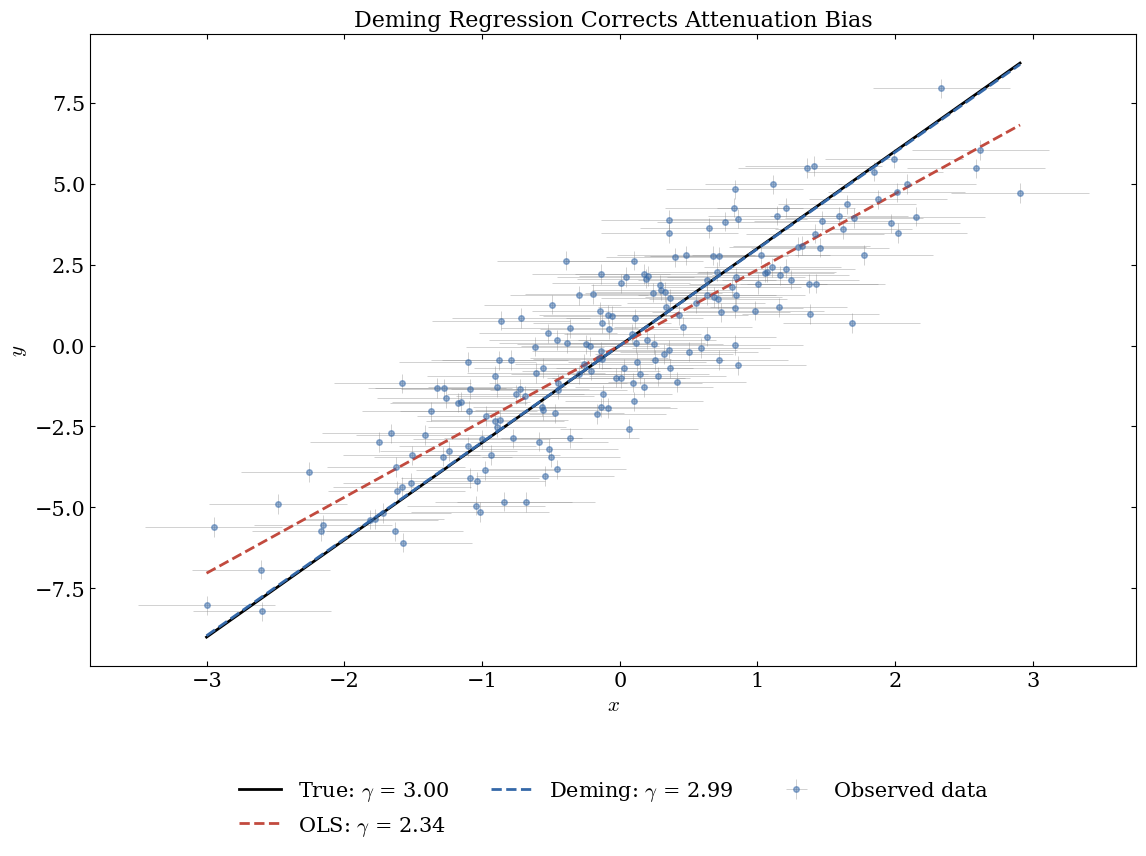

In [9]:
# Visualize the comparison
plt.figure(figsize=(13.5, 8.2))
plt.errorbar(x_centered, y_centered, xerr=sigma_x, yerr=sigma_y,
             fmt='o', markersize=4, alpha=0.5, ecolor='gray',
             elinewidth=0.5, capsize=0, label='Observed data')

# Plot the true line, the OLS fit and the Deming fit
x_line = np.linspace(x_centered.min(), x_centered.max(), 100)
plt.plot(x_line, true_slope * x_line, '-', color='k', linewidth=2,
         label=f'True: $\\gamma$ = {true_slope:.2f}')
plt.plot(x_line, gamma_ols * x_line, '--', color='C3', linewidth=2,
         label=f'OLS: $\\gamma$ = {gamma_ols:.2f}')
plt.plot(x_line, gamma_deming * x_line, '--', color='C0', linewidth=2,
         label=f'Deming: $\\gamma$ = {gamma_deming:.2f}')

# Label the axes, add the title and the legend
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Deming Regression Corrects Attenuation Bias')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

Deming regression corrects most of the attenuation bias. OLS underestimates the slope by a large amount, and Deming regression recovers a value much closer to the true slope. We want to know whether the remaining difference from the true slope is within the expected statistical variation. For this, we use bootstrap resampling (Section 3.7) to estimate the uncertainty of our estimates. Each resample draws the same number of points with replacement from the simulated data, and we compute both slopes again. We repeat this 1000 times.

In [10]:
# Bootstrap the slope estimates
n_bootstrap = 1000
ols_slopes = []
deming_slopes = []

for _ in range(n_bootstrap):
    # Resample with replacement
    idx = np.random.choice(n_points, n_points, replace=True)
    x_boot = x_centered[idx]
    y_boot = y_centered[idx]

    # OLS estimate
    gamma_ols_boot = np.sum(x_boot * y_boot) / np.sum(x_boot**2)
    ols_slopes.append(gamma_ols_boot)

    # Deming estimate
    Sxx_boot = np.sum(x_boot**2)
    Syy_boot = np.sum(y_boot**2)
    Sxy_boot = np.sum(x_boot * y_boot)
    gamma_deming_boot = (Syy_boot - lam*Sxx_boot +
                         np.sqrt((Syy_boot - lam*Sxx_boot)**2 + 4*lam*Sxy_boot**2)) / (2*Sxy_boot)
    deming_slopes.append(gamma_deming_boot)

ols_slopes = np.array(ols_slopes)
deming_slopes = np.array(deming_slopes)

We plot the distribution of each slope and print the 95% intervals, from the 2.5th and 97.5th percentiles.

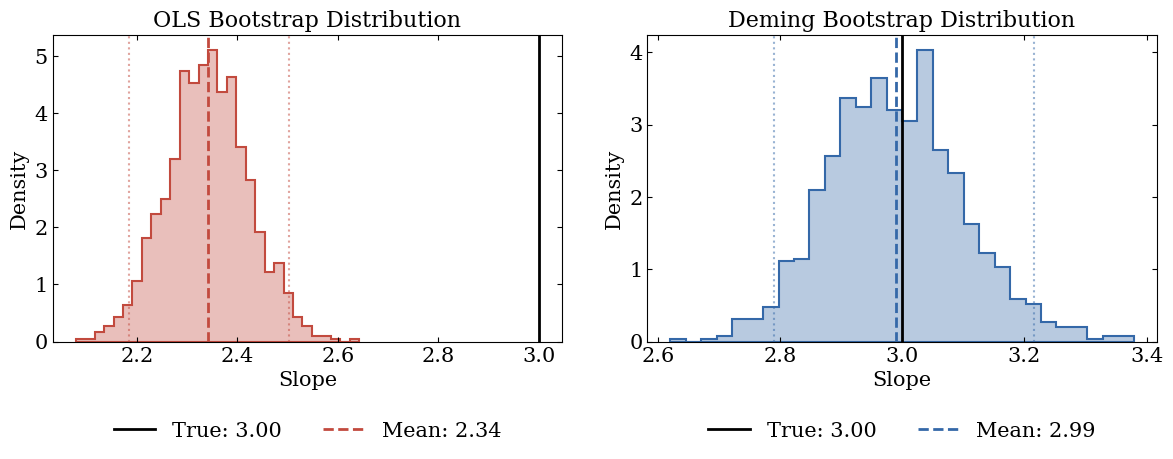

OLS 95% CI = [2.185, 2.502]
Deming 95% CI = [2.790, 3.216]


In [11]:
# Plot the distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# OLS distribution
ax1.hist(ols_slopes, bins=30, density=True,
         histtype='stepfilled', facecolor=('C3', 0.35), edgecolor='C3', linewidth=1.5)
ax1.axvline(true_slope, color='black', linestyle='-', linewidth=2, label=f'True: {true_slope:.2f}')
ax1.axvline(np.mean(ols_slopes), color='C3', linestyle='--', linewidth=2,
            label=f'Mean: {np.mean(ols_slopes):.2f}')
ax1.axvline(np.percentile(ols_slopes, 2.5), color='C3', linestyle=':', alpha=0.5)
ax1.axvline(np.percentile(ols_slopes, 97.5), color='C3', linestyle=':', alpha=0.5)
ax1.set_xlabel('Slope')
ax1.set_ylabel('Density')
ax1.set_title('OLS Bootstrap Distribution')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

# Deming distribution
ax2.hist(deming_slopes, bins=30, density=True,
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
ax2.axvline(true_slope, color='black', linestyle='-', linewidth=2, label=f'True: {true_slope:.2f}')
ax2.axvline(np.mean(deming_slopes), color='C0', linestyle='--', linewidth=2,
            label=f'Mean: {np.mean(deming_slopes):.2f}')
ax2.axvline(np.percentile(deming_slopes, 2.5), color='C0', linestyle=':', alpha=0.5)
ax2.axvline(np.percentile(deming_slopes, 97.5), color='C0', linestyle=':', alpha=0.5)
ax2.set_xlabel('Slope')
ax2.set_ylabel('Density')
ax2.set_title('Deming Bootstrap Distribution')
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

plt.tight_layout()
plt.show()

# Calculate the 95% intervals, from the 2.5th and 97.5th percentiles
ols_ci = np.percentile(ols_slopes, [2.5, 97.5])
deming_ci = np.percentile(deming_slopes, [2.5, 97.5])

# Print the 95% intervals
print(f"OLS 95% CI = [{ols_ci[0]:.3f}, {ols_ci[1]:.3f}]")
print(f"Deming 95% CI = [{deming_ci[0]:.3f}, {deming_ci[1]:.3f}]")

The dotted lines mark the 95% intervals. The OLS distribution is centered far from the true value, and the bias from the attenuation is much larger than the statistical uncertainty. In contrast, the interval of the Deming slopes contains the true slope.

## Heteroscedastic Uncertainties: The Realistic Case

Our analysis so far assumed constant measurement uncertainties for all data points. Real astronomical data rarely satisfy this assumption. Brighter objects typically have more precise measurements than fainter ones, and different observational techniques give different uncertainties.

For heteroscedastic uncertainties, which vary from point to point, Deming regression extends to the general case (Section 6.8) but loses its simple analytical form. For $N$ points with the data centered on their means, the slope $\gamma$ must satisfy

$$F(\gamma) = \sum_{i=1}^N \frac{(\sigma_{y,i}^2 x_{\text{obs},i} + \gamma \sigma_{x,i}^2 y_{\text{obs},i})(y_{\text{obs},i} - \gamma x_{\text{obs},i})}{(\sigma_{y,i}^2 + \gamma^2 \sigma_{x,i}^2)^2} = 0.$$

Section 6.8 derives this condition after it eliminates the true $x$-values. Unlike the homoscedastic case, the equation does not reduce to a quadratic, so we must solve it numerically. The slope is one number, so a grid search is enough. We evaluate $F$ on a grid of slopes and take the slope where $F$ is closest to zero. The plot of $F$ below shows this zero.

To test this extension, we simulate data with the same true slope. The uncertainties grow with the distance of a point from the center, as in real data where fainter objects have larger errors. The $x$-uncertainty is 0.2 at the center and 0.4 at $|x_{\text{true}}| = 1$, and the $y$-uncertainty is 0.1 and 0.2 at these points.

In [12]:
# Simulate data with heteroscedastic uncertainties
n_points = 200
true_slope = 3.0
x_sd = 1.0  # standard deviation of the true x-values

# Generate the true values
x_true = np.random.normal(0, x_sd, n_points)
y_true = true_slope * x_true

# Create varying uncertainties, larger for points further from the center
# This mimics real data where fainter or more distant objects have larger errors
sigma_x_het = 0.2 + 0.2 * np.abs(x_true) / x_sd  # 0.2 at the center and 0.4 at |x_true| = 1
sigma_y_het = 0.1 + 0.1 * np.abs(x_true) / x_sd  # 0.1 at the center and 0.2 at |x_true| = 1

# Add measurement errors with varying uncertainties
x_obs = x_true + np.random.normal(0, sigma_x_het)
y_obs = y_true + np.random.normal(0, sigma_y_het)

# Center the observed data
x_centered = x_obs - np.mean(x_obs)
y_centered = y_obs - np.mean(y_obs)
sigma_x_centered = sigma_x_het  # Uncertainties do not change with centering
sigma_y_centered = sigma_y_het

We now fit the data. OLS ignores the $x$-uncertainties. For the Deming fit, we code the function $F$ and search a grid of slopes for the one where $F$ is closest to zero. The grid runs from 1 to 10, because we expect a positive slope.

In [13]:
# OLS, which ignores the x-uncertainties
gamma_ols = np.sum(x_centered * y_centered) / np.sum(x_centered**2)

# Define the function F of Section 6.8, for an array of slopes
def deming_objective(gamma, x, y, e_x, e_y):
    gamma = gamma[:, None]
    numerator = e_y**2 * x + gamma * e_x**2 * y
    denominator = e_y**2 + gamma**2 * e_x**2
    return np.sum(numerator / denominator**2 * (y - gamma * x), axis=1)

# The Deming slope is the grid value of the slope where F is closest to zero
def deming_slope(x, y, e_x, e_y, gamma_grid=np.linspace(1.0, 10.0, 9001)):
    return gamma_grid[np.argmin(np.abs(deming_objective(gamma_grid, x, y, e_x, e_y)))]

gamma_deming_het = deming_slope(x_centered, y_centered, sigma_x_centered, sigma_y_centered)

We plot the data with the three lines, and the function $F(\gamma)$ with the three slopes.

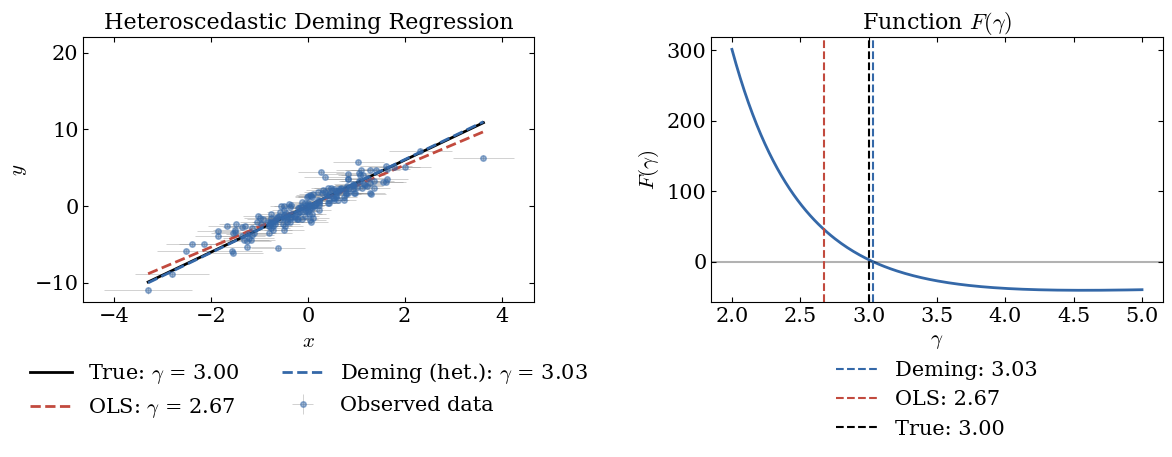

In [14]:
# Visualize
plt.figure(figsize=(12, 5))

# Left panel with the data and the varying error bars
plt.subplot(1, 2, 1)
plt.errorbar(x_centered, y_centered, xerr=sigma_x_centered, yerr=sigma_y_centered,
             fmt='o', markersize=4, alpha=0.5, ecolor='gray',
             elinewidth=0.5, capsize=0, label='Observed data')

# Plot the true line, the OLS fit and the Deming fit
x_line = np.linspace(x_centered.min(), x_centered.max(), 100)
plt.plot(x_line, true_slope * x_line, '-', color='k', linewidth=2,
         label=f'True: $\\gamma$ = {true_slope:.2f}')
plt.plot(x_line, gamma_ols * x_line, '--', color='C3', linewidth=2,
         label=f'OLS: $\\gamma$ = {gamma_ols:.2f}')
plt.plot(x_line, gamma_deming_het * x_line, '--', color='C0', linewidth=2,
         label=f'Deming (het.): $\\gamma$ = {gamma_deming_het:.2f}')

# Label the axes, add the title, the legend and the limits
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.title('Heteroscedastic Deming Regression')
plt.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.ylim(top=22)

# Right panel with the function F
plt.subplot(1, 2, 2)
gamma_range = np.linspace(2, 5, 200)
F_vals = deming_objective(gamma_range, x_centered, y_centered, sigma_x_centered, sigma_y_centered)

# Plot F with the three slopes
plt.plot(gamma_range, F_vals, '-', color='C0', linewidth=2)
plt.axhline(0, color='k', linestyle='-', alpha=0.3)
plt.axvline(gamma_deming_het, color='C0', linestyle='--',
            label=f'Deming: {gamma_deming_het:.2f}')
plt.axvline(gamma_ols, color='C3', linestyle='--',
            label=f'OLS: {gamma_ols:.2f}')
plt.axvline(true_slope, color='k', linestyle='--',
            label=f'True: {true_slope:.2f}')

plt.xlabel('$\\gamma$')
plt.ylabel('$F(\\gamma)$')
plt.title('Function $F(\\gamma)$')
plt.legend(ncol=1, loc='upper center', bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
plt.show()

The Deming fit recovers the true slope well even when the uncertainties differ from point to point. The right panel shows the function $F(\gamma)$, which crosses zero smoothly at the Deming solution. OLS ignores the $x$-uncertainties, and it stays biased whether they are constant or differ from point to point.

## Forward vs Inverse Regression: A Common Confusion

Before we apply Deming regression to the SPARC data, we address a common source of confusion in astronomical scaling relations. When we fit the Tully-Fisher relation, we can regress the mass on the velocity ($M$ against $V$). We can also regress the velocity on the mass ($V$ against $M$). With OLS, these two choices give different results, and the slopes are not simply reciprocals of each other.

This asymmetry arises because OLS minimizes the residuals in one direction only. Forward regression, with $V$ as $x$ and $M$ as $y$, minimizes the vertical residuals. Inverse regression, with $M$ as $x$ and $V$ as $y$, minimizes the horizontal residuals. The choice matters, because it assumes that one variable is measured perfectly.

In the SPARC dataset, the reported mass uncertainty is much smaller than the velocity uncertainty. From a statistical perspective, we should use the mass as the independent variable. However, astronomical convention plots the velocity on the $x$-axis of the Tully-Fisher relation. This creates a dilemma between statistical practice and astronomical convention.

Deming regression removes this tension. It treats both variables symmetrically and uses the uncertainties in both dimensions. The result does not depend on which variable we call $x$ or $y$, so we get the same relation either way. We show this with the SPARC data.

We center the data and compute four slopes. The forward and inverse fits are OLS with the roles of the variables exchanged, and the Deming fit uses the uncertainties of both variables. We also repeat the Deming fit with $x$ and $y$ exchanged.

In [15]:
# Center the SPARC data
x_centered = x_gal - np.mean(x_gal)
y_centered = y_gal - np.mean(y_gal)

# Forward regression with V as x and M as y, the astronomical convention
gamma_forward = np.sum(x_centered * y_centered) / np.sum(x_centered**2)

# Inverse regression with M as x and V as y, preferred by the uncertainties
gamma_inverse_raw = np.sum(x_centered * y_centered) / np.sum(y_centered**2)

# Take the reciprocal to get a comparable slope of M against V
gamma_inverse = 1.0 / gamma_inverse_raw

# Heteroscedastic Deming regression
gamma_deming = deming_slope(x_centered, y_centered, sigma_x_gal, sigma_y_gal)

# Deming regression with x and y swapped, which gives the slope of V against M
gamma_swapped = deming_slope(y_centered, x_centered, sigma_y_gal, sigma_x_gal,
                             np.linspace(0.05, 1.0, 95001))

# Print the Deming slope and the slope of the swapped fit
print(f"Deming regression, γ = {gamma_deming:.3f}")
print(f"Deming regression with x and y swapped, 1/γ = {gamma_swapped:.3f} → γ = {1/gamma_swapped:.3f}")

Deming regression, γ = 4.135
Deming regression with x and y swapped, 1/γ = 0.242 → γ = 4.135


We plot the three fits with the error bars of both variables. In the inverse fit, the velocity is on the vertical axis.

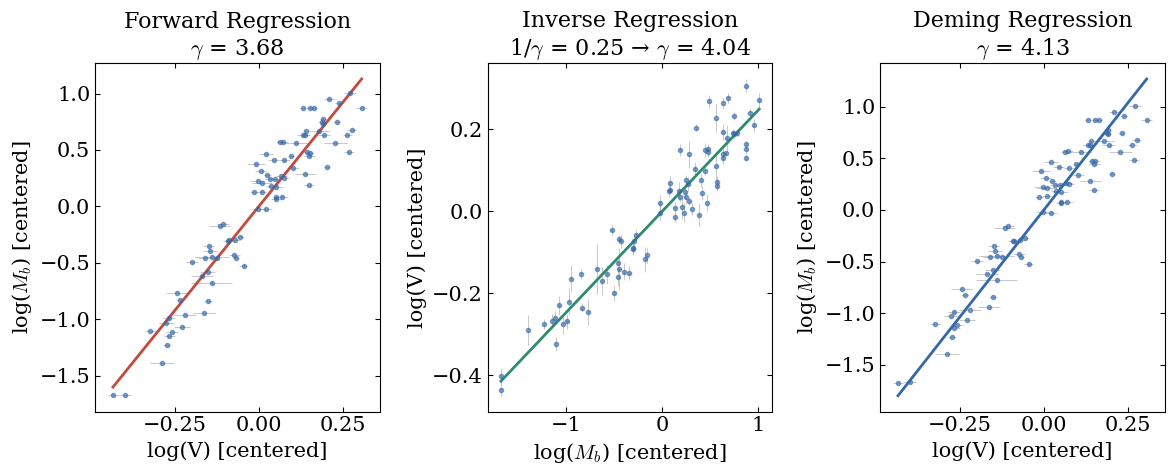

In [16]:
# Visualize the different approaches
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Forward regression plot, with the error bars of both variables
axes[0].errorbar(x_centered, y_centered, xerr=sigma_x_gal, yerr=sigma_y_gal,
                 fmt='o', markersize=3, alpha=0.6, ecolor='gray',
                 elinewidth=0.5, capsize=0)
x_line = np.linspace(x_centered.min(), x_centered.max(), 100)
axes[0].plot(x_line, gamma_forward * x_line, '-', color='C3', linewidth=2)
axes[0].set_xlabel('log(V) [centered]')
axes[0].set_ylabel(r'log($M_b$) [centered]')
axes[0].set_title(f'Forward Regression\n$\\gamma$ = {gamma_forward:.2f}')

# Inverse regression plot, with the error bars of both variables
axes[1].errorbar(y_centered, x_centered, xerr=sigma_y_gal, yerr=sigma_x_gal,
                 fmt='o', markersize=3, alpha=0.6, ecolor='gray',
                 elinewidth=0.5, capsize=0)
y_line = np.linspace(y_centered.min(), y_centered.max(), 100)
axes[1].plot(y_line, gamma_inverse_raw * y_line, '-', color='C2', linewidth=2)
axes[1].set_xlabel(r'log($M_b$) [centered]')
axes[1].set_ylabel('log(V) [centered]')
axes[1].set_title(f'Inverse Regression\n1/$\\gamma$ = {gamma_inverse_raw:.2f} → $\\gamma$ = {gamma_inverse:.2f}')

# Deming regression plot, with the error bars of both variables
axes[2].errorbar(x_centered, y_centered, xerr=sigma_x_gal, yerr=sigma_y_gal,
                 fmt='o', markersize=3, alpha=0.6, ecolor='gray',
                 elinewidth=0.5, capsize=0)
axes[2].plot(x_line, gamma_deming * x_line, '-', color='C0', linewidth=2)
axes[2].set_xlabel('log(V) [centered]')
axes[2].set_ylabel(r'log($M_b$) [centered]')
axes[2].set_title(f'Deming Regression\n$\\gamma$ = {gamma_deming:.2f}')

plt.tight_layout()
plt.show()

The forward slope is 3.68 and the inverse slope is 4.04. The Deming slope is about 4.1, close to the inverse slope. The reported mass uncertainty is much smaller than the velocity uncertainty, so Deming regression gives the mass more weight. The Deming fit with $x$ and $y$ exchanged gives the same slope after the inversion.

The same reason makes the inverse slope, which has the mass as the independent variable, nearly free of attenuation. Suppose velocity errors alone cause the difference between the slopes. The inverse slope then equals $\gamma$ and the forward slope is $\alpha\gamma$, so the data give the attenuation factor,

$$\alpha = \frac{\text{forward slope}}{\text{inverse slope}} = \frac{3.68}{4.04} = 0.91.$$

The reported uncertainties predict a different value. The velocity uncertainties are about 9% of the standard deviation of $x$, so

$$\alpha \approx \frac{1}{1 + 0.09^2} \approx 0.99.$$

This is far from 0.91. If the relation is a straight line, the reported uncertainties therefore miss a systematic uncertainty. The galaxies also scatter about the line by more than their reported errors, as the error bars of the figure show. For this study we assume that the missing uncertainty belongs to the velocity, for example systematic errors in the inclination. We add a systematic uncertainty $\sigma_{\text{sys}}$ in quadrature to the reported velocity uncertainty $\sigma_{\text{rep},i}$ of every galaxy,

$$\sigma_{x,i}^2 = \sigma_{\text{rep},i}^2 + \sigma_{\text{sys}}^2.$$

## Choosing the Systematic Uncertainty

We reuse the attenuation factor. In the simulation, we knew the velocity error and predicted how much it flattens the OLS slope. Now we go the other way. The data give the attenuation factor of 0.91, and the same formula gives the error that causes it.

In Section 6.3, $\alpha$ is the variance of the true velocities over the variance of the observed velocities. The observed variance is $\sigma_{\text{obs}}^2 = \sigma_{\text{range}}^2 + \sigma_x^2$, so

$$\alpha = \frac{\sigma_{\text{range}}^2}{\sigma_{\text{obs}}^2} = 1 - \frac{\sigma_x^2}{\sigma_{\text{obs}}^2}.$$

When the uncertainties differ between galaxies, $\sigma_x^2$ is their mean square. We compute $\sigma_{\text{obs}}^2$ from the observed velocities. The two expressions for $\alpha$, from the slopes and from the uncertainties, describe the same quantity, so we set them equal and solve for $\sigma_x^2$. With $\sigma_{x,i}^2 = \sigma_{\text{rep},i}^2 + \sigma_{\text{sys}}^2$, the result is

$$\sigma_{\text{sys}}^2 = (1 - \alpha)\,\sigma_{\text{obs}}^2 - \sigma_{\text{rep}}^2,$$

where $\sigma_{\text{rep}}^2$ is the mean square of the reported uncertainties.

We now compute $\sigma_{\text{sys}}$ from the two slopes.

In [17]:
# Variance of the observed velocities and mean square of the reported uncertainties
sigma_obs2 = np.var(x_centered)
sigma_rep2 = np.mean(sigma_x_gal**2)

# Attenuation factor, the forward slope over the inverse slope
alpha = gamma_forward / gamma_inverse

# Systematic uncertainty that gives this attenuation
sigma_sys = np.sqrt((1 - alpha) * sigma_obs2 - sigma_rep2)
sigma_x_total = np.sqrt(sigma_x_gal**2 + sigma_sys**2)
print(f"Attenuation factor = {alpha:.2f}")
print(f"Systematic velocity uncertainty = {sigma_sys:.3f} dex")

Attenuation factor = 0.91
Systematic velocity uncertainty = 0.048 dex


## Checking the Uncertainties Against the Scatter

The two slopes give an attenuation factor of 0.91 and a systematic uncertainty of about 0.05 dex, three times the median reported velocity uncertainty. This step ignores the mass uncertainty $\sigma_{y,i}$. More properly, the mass uncertainty should enter too.

We check with the residuals of the fit whether the inflated uncertainties describe the scatter. If the centered data follow the line, the residual $y_i - \gamma x_i$ of galaxy $i$ is the error in $y_i$ minus $\gamma$ times the error in $x_i$. The two errors are independent. By the rules for sums of random variables in Section 3.5, the variance of the residual is

$$\mathrm{Var}[y_i - \gamma x_i] = \sigma_{y,i}^2 + \gamma^2\sigma_{x,i}^2.$$

The normalized residual is the residual divided by its standard deviation,

$$\frac{y_i - \gamma x_i}{\sqrt{\sigma_{y,i}^2 + \gamma^2\sigma_{x,i}^2}}.$$

If the uncertainties describe the scatter, the horizontal error bars reach the line for about two thirds of the galaxies. The normalized residuals then have a standard deviation of about 1, and the mean of their squares is about 1. This is the square of the normalized error of Tutorial 5, now with errors in both variables.

The slope $\gamma$ is the Deming slope for the uncertainties. We fit it with the inflated uncertainties and compute the mean squared normalized residual for the reported and for the inflated uncertainties.

In [18]:
# Deming regression with the inflated uncertainties
gamma_deming_sys = deming_slope(x_centered, y_centered, sigma_x_total, sigma_y_gal)
print(f"Deming slope with the inflated uncertainties = {gamma_deming_sys:.3f}")

# Mean squared normalized residual of the Deming fit for each set of uncertainties
for label, sigma_x, gamma in [('reported', sigma_x_gal, gamma_deming), ('inflated', sigma_x_total, gamma_deming_sys)]:
    residuals = (y_centered - gamma * x_centered) / np.sqrt(sigma_y_gal**2 + gamma**2 * sigma_x**2)
    print(f"Mean squared normalized residual, {label} uncertainties = {np.mean(residuals**2):.2f}")

Deming slope with the inflated uncertainties = 4.036
Mean squared normalized residual, reported uncertainties = 13.83
Mean squared normalized residual, inflated uncertainties = 1.03


The inflated uncertainties give a mean squared normalized residual of 1.03, against 13.8 for the reported ones, so they describe the scatter.

The check also suggests another way to choose $\sigma_{\text{sys}}$. Without the estimate from the attenuation, we could search for the value at which the mean squared normalized residual equals 1. This is more principled, because it uses the uncertainty of each galaxy and not their mean, and it includes $\sigma_{y,i}$ when needed. We do not need the search here, because the estimate already gives a value of about 1.

## Deming Regression with the Inflated Uncertainties

Given these uncertainties, the Deming fit gives the slope of the relation. The forward OLS fit shows what ignoring the velocity errors gives. We plot the galaxies with the inflated velocity uncertainties and both fits.

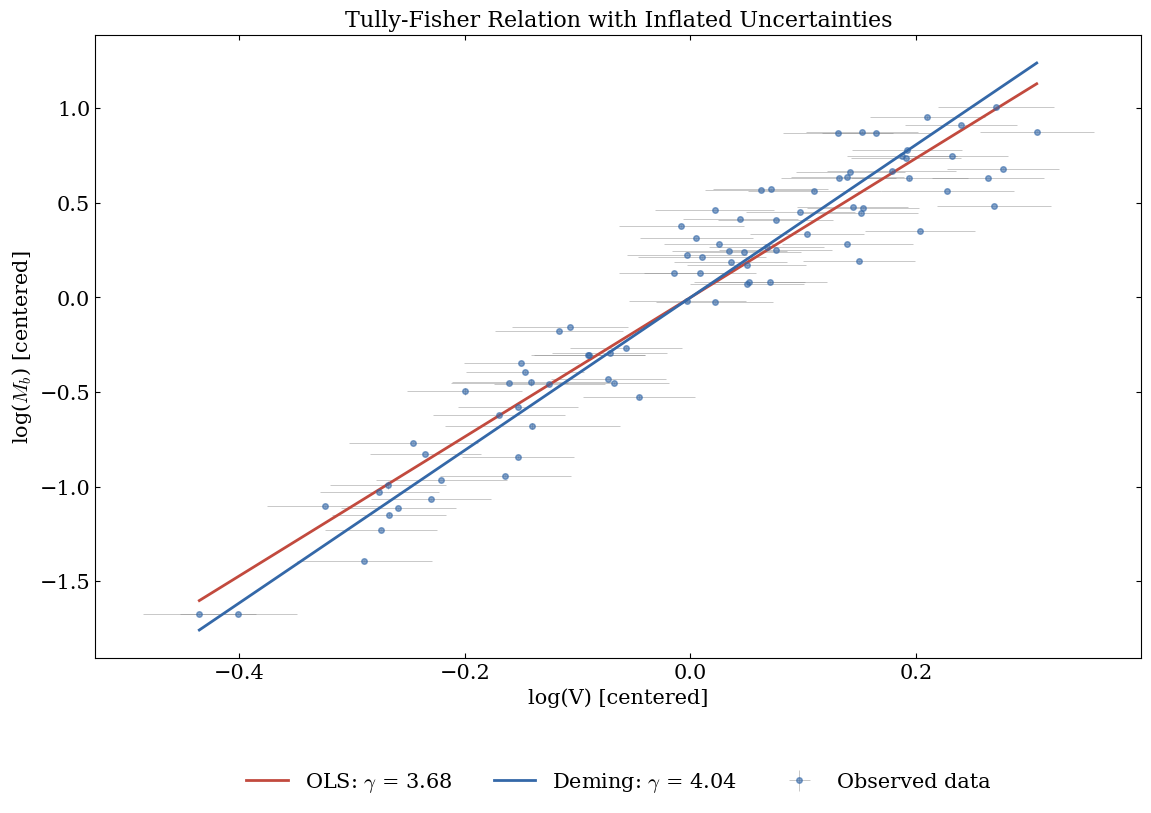

In [19]:
# Plot the galaxies with the error bars of both variables
plt.figure(figsize=(13.5, 8.1))
plt.errorbar(x_centered, y_centered, xerr=sigma_x_total, yerr=sigma_y_gal,
             fmt='o', markersize=4, alpha=0.6, ecolor='gray',
             elinewidth=0.5, capsize=0, label='Observed data')

# Plot the forward OLS fit and the Deming fit
x_line = np.linspace(x_centered.min(), x_centered.max(), 100)
plt.plot(x_line, gamma_forward * x_line, '-', color='C3', linewidth=2,
         label=f'OLS: $\\gamma$ = {gamma_forward:.2f}')
plt.plot(x_line, gamma_deming_sys * x_line, '-', color='C0', linewidth=2,
         label=f'Deming: $\\gamma$ = {gamma_deming_sys:.2f}')

# Label the axes, add the title and the legend
plt.xlabel('log(V) [centered]')
plt.ylabel(r'log($M_b$) [centered]')
plt.title('Tully-Fisher Relation with Inflated Uncertainties')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

The inflated error bars reach the lines. Deming regression with the inflated uncertainties gives a slope of 4.04, close to the inverse slope, because the velocity now carries almost all the uncertainty. Attenuation bias therefore explains why the Deming line is steeper than the OLS line, and Deming regression corrects it.

## Bootstrap Uncertainty for the Tully-Fisher Relation

We now estimate the uncertainty of each slope with bootstrap resampling of the SPARC data. This shows whether the difference between the OLS and Deming slopes is larger than the sampling noise. We run the Deming regression for every resample with the same grid search. It uses the inflated uncertainties, with $\sigma_{\text{sys}}$ fixed at the value from the full sample. Each resample draws galaxies with replacement together with their uncertainties and computes the two slopes.

In [20]:
# Bootstrap the SPARC slope estimates
n_bootstrap = 1000
n_galaxies = len(x_gal)

forward_slopes = []
deming_slopes = []

for _ in range(n_bootstrap):
    # Resample with replacement
    idx = np.random.choice(n_galaxies, n_galaxies, replace=True)

    # Get the resampled data
    x_boot = x_centered[idx]
    y_boot = y_centered[idx]
    e_x_boot = sigma_x_total[idx]
    e_y_boot = sigma_y_gal[idx]

    # Forward regression, which is OLS
    gamma_forward_boot = np.sum(x_boot * y_boot) / np.sum(x_boot**2)
    forward_slopes.append(gamma_forward_boot)

    # Deming regression
    gamma_deming_boot = deming_slope(x_boot, y_boot, e_x_boot, e_y_boot)
    deming_slopes.append(gamma_deming_boot)

# Convert to arrays
forward_slopes = np.array(forward_slopes)
deming_slopes = np.array(deming_slopes)

We plot the distribution of each slope and print the 95% intervals and the standard errors.

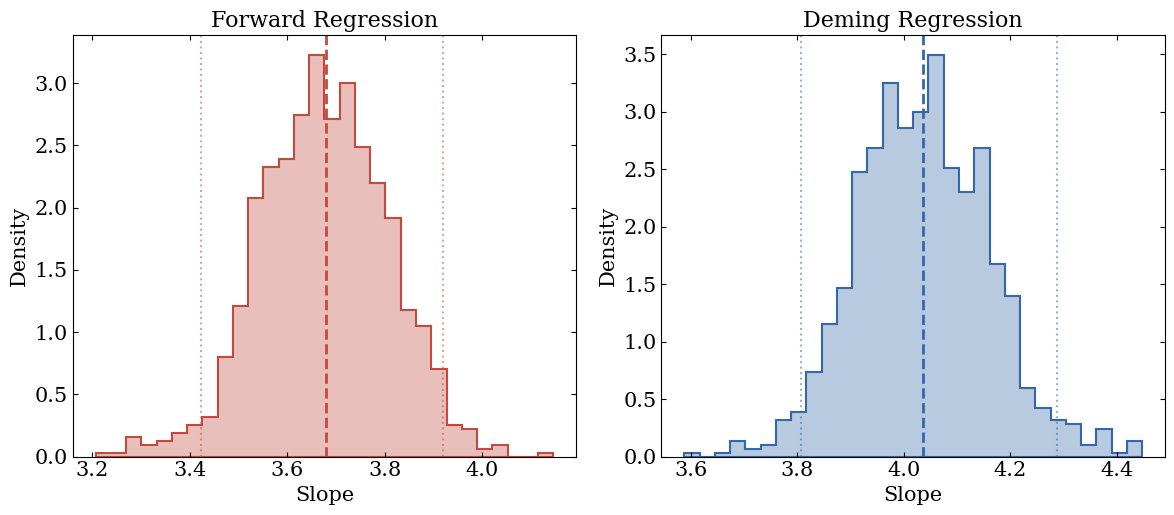

Tully-Fisher slope estimates (95% CI)
Forward = 3.679 [3.424, 3.921]
Deming = 4.036 [3.807, 4.287]

Standard errors
Forward = 0.130
Deming = 0.124


In [21]:
# Calculate the 95% intervals
forward_ci = np.percentile(forward_slopes, [2.5, 97.5])  # 2.5th and 97.5th percentiles
deming_ci = np.percentile(deming_slopes, [2.5, 97.5])  # 2.5th and 97.5th percentiles

# Visualize the bootstrap distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 5.4))

# Forward regression distribution
ax1.hist(forward_slopes, bins=30, density=True,
         histtype='stepfilled', facecolor=('C3', 0.35), edgecolor='C3', linewidth=1.5)
ax1.axvline(gamma_forward, color='C3', linestyle='--', linewidth=2)
ax1.axvline(forward_ci[0], color='C3', linestyle=':', alpha=0.5)
ax1.axvline(forward_ci[1], color='C3', linestyle=':', alpha=0.5)
ax1.set_xlabel('Slope')
ax1.set_ylabel('Density')
ax1.set_title('Forward Regression')

# Deming regression distribution
ax2.hist(deming_slopes, bins=30, density=True,
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
ax2.axvline(gamma_deming_sys, color='C0', linestyle='--', linewidth=2)
ax2.axvline(deming_ci[0], color='C0', linestyle=':', alpha=0.5)
ax2.axvline(deming_ci[1], color='C0', linestyle=':', alpha=0.5)
ax2.set_xlabel('Slope')
ax2.set_ylabel('Density')
ax2.set_title('Deming Regression')

plt.tight_layout()
plt.show()

# Print the results
print("Tully-Fisher slope estimates (95% CI)")
print(f"Forward = {gamma_forward:.3f} [{forward_ci[0]:.3f}, {forward_ci[1]:.3f}]")
print(f"Deming = {gamma_deming_sys:.3f} [{deming_ci[0]:.3f}, {deming_ci[1]:.3f}]")
print("\nStandard errors")
print(f"Forward = {np.std(forward_slopes):.3f}")
print(f"Deming = {np.std(deming_slopes):.3f}")

The dashed lines mark the slopes from the full sample, and the dotted lines mark the 95% intervals. The forward distribution is centered near 3.7, and the Deming distribution near 4.0. The difference between the forward and the Deming slope is larger than the standard error of either slope. Sampling noise is therefore unlikely to explain it.

For these galaxies, the choice of the fit changes the slope by about 10%. This matters, because the Tully-Fisher slope constrains galaxy formation and sets distances, as the relation is a rung of the cosmic distance ladder.

The steps of this analysis apply to other relations with errors in both variables. First compute the attenuation factor from the reported uncertainties. If the forward and inverse slopes show more attenuation than the reported uncertainties explain, state where the extra uncertainty lies. Infer its size from the attenuation, and check the result with the normalized residuals. Finally, fit with Deming regression and estimate the uncertainty of the slope with the bootstrap.

## Limits of the Assumption

These steps rest on one assumption. We assumed that the extra scatter belongs to the velocity. The data alone cannot show this, because a straight-line fit sees only the total scatter and not how it splits between the two variables. The split must come from outside the data.

The mass can contribute to the scatter too. The reported mass uncertainty comes from the photometry alone, and the distance and the conversion from light to mass add more. The relation may also have an intrinsic scatter.

Suppose the extra scatter lay in the mass. Then the forward OLS slope would be closer to the truth, and the Deming slope would be too steep. The slope of about 4 is therefore a result under our assumption.

## Summary

This tutorial showed how measurement uncertainties in the independent variable lead to attenuation bias, through the Tully-Fisher relation. We explored the following concepts.

1. **Attenuation bias in regression.** Attenuation bias arises when measurement uncertainties in the independent variable inflate the observed spread and flatten the measured relation. The bias remains whatever the sample size. It depends on the ratio of the measurement uncertainty to the intrinsic spread.

2. **Deming regression solution.** Deming regression corrects the attenuation bias. It treats the true values as latent variables and infers them together with the model parameters. It recovered the true slope in our simulations, where the measurement errors were the only scatter. It reduces to OLS when the uncertainties in $x$ approach zero.

3. **Practical implementation.** For homoscedastic uncertainties, Deming regression has a closed-form solution. For heteroscedastic uncertainties, which are common in astronomical data, a grid search gives the solution. Bootstrap resampling estimates the uncertainty of the slopes.

4. **Systematic uncertainty.** Reported uncertainties can miss a systematic part. With a proper assumption about where it lies, we can estimate it from the data, and Deming regression can account for it. The fitted slope is then a result under that assumption.

The techniques apply whenever we measure relations between quantities that both carry measurement uncertainties. This is a common situation in observational astronomy, where perfect measurements do not exist.